# BFC Competitor Check 2026
## Notebook 08: Visualization and Recommendations

### Purpose

Communicate supported findings and propose practical actions
linked to RQ01 through RQ10.

### Reporting Rules

Distinguish recorded observations from verified comparisons.

Keep customer coding explicitly provisional.

Do not interpret collection counts as market share,
product breadth or business performance.

Recommendations must identify the supporting evidence,
proposed action, owner role and success measure.

### 1. Evidence Coverage

This chart shows how many of the 23 registered brands have
at least one record in each dataset.

The denominator includes BFC, included competitors and
candidate brands.

A recorded entry does not establish complete or comparable
coverage. No entry means evidence was not collected.

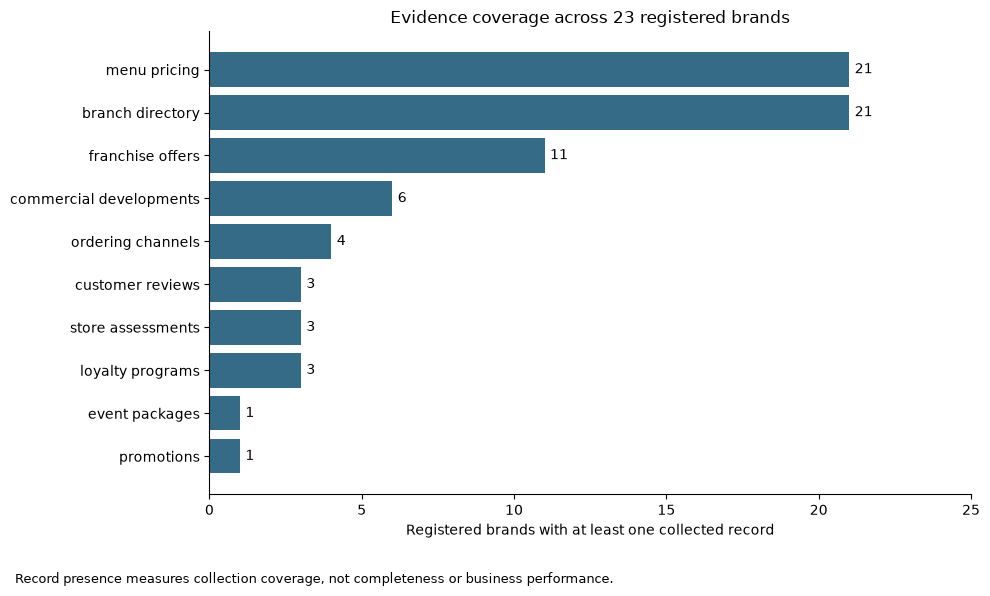

,dataset,records,brands_with_records,registered_brands,coverage_percent
0,branch_directory,24,21,23,91.3
1,menu_pricing,129,21,23,91.3
2,promotions,1,1,23,4.3
3,loyalty_programs,3,3,23,13.0
4,store_assessments,3,3,23,13.0
5,customer_reviews,36,3,23,13.0
6,ordering_channels,5,4,23,17.4
7,franchise_offers,15,11,23,47.8
8,commercial_developments,7,6,23,26.1
9,event_packages,12,1,23,4.3


Source: reports/eda/coverage_summary.csv
Chart displayed only. No files changed.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the saved EDA outputs.

project_root = Path.cwd().resolve()

while (
    not (
        project_root / "reports" / "eda" / "coverage_summary.csv"
    ).is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

eda_path = project_root / "reports" / "eda"
coverage_path = eda_path / "coverage_summary.csv"

if not coverage_path.is_file():
    raise FileNotFoundError(
        "Run Notebook 04 and save its EDA outputs first."
    )

coverage_summary = pd.read_csv(coverage_path, dtype="string")

numeric_columns = [
    "records",
    "brands_with_records",
    "registered_brands",
    "coverage_percent",
]

for column in numeric_columns:
    coverage_summary[column] = pd.to_numeric(
        coverage_summary[column],
        errors="raise",
    )

chart_data = coverage_summary.sort_values("brands_with_records")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    chart_data["dataset"].str.replace("_", " ", regex=False),
    chart_data["brands_with_records"],
    color="#356B87",
)

ax.bar_label(bars, padding=4, fmt="%.0f")

ax.set_xlim(0, chart_data["registered_brands"].max() + 2)
ax.set_xlabel("Registered brands with at least one collected record")
ax.set_title("Evidence coverage across 23 registered brands")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02,
    0.02,
    "Record presence measures collection coverage, not completeness "
    "or business performance.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

display(coverage_summary)

print("Source: reports/eda/coverage_summary.csv")
print("Chart displayed only. No files changed.")

## 2. Candidate Published Menu Prices

### Research Question

RQ01: How does BFC pricing compare with equivalent competitor products?

### Purpose

Display recorded BFC and CBTL prices for three drink groups
with matching 12oz and 16oz cup labels.

Iced records are displayed to avoid repeating the identical
hot price patterns.

### Qualifications

These are candidate comparisons from selected published menus.

Recipe equivalence, price freshness and branch applicability
remain unresolved. Matching cup labels do not establish actual
beverage volume or customer value.

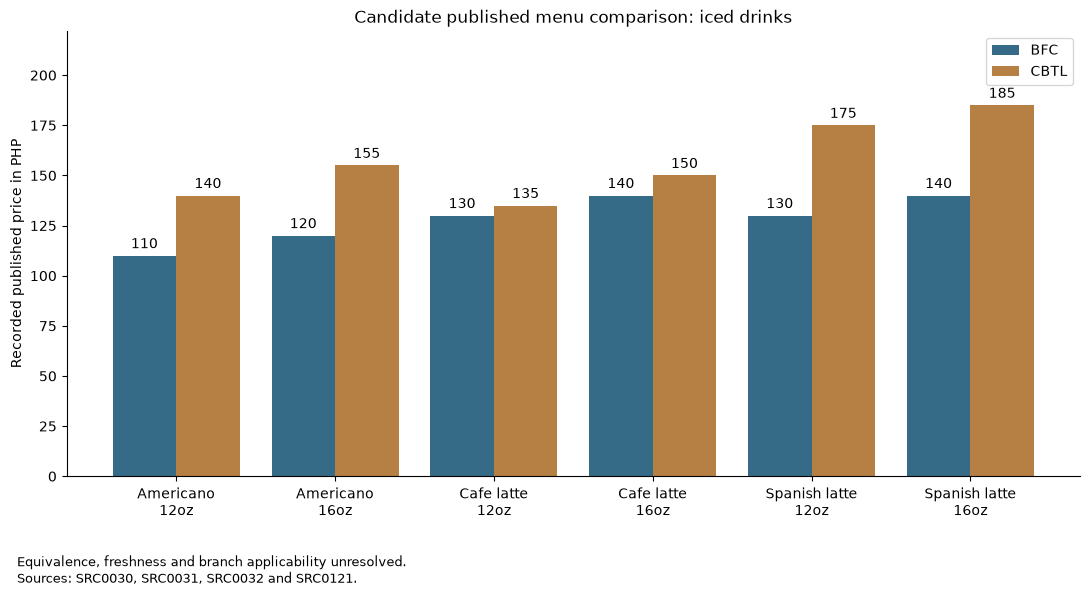

,comparison_group,size_label_standardised,displayed_price_php_bfc,displayed_price_php_cbtl,cbtl_minus_bfc_php
6,Americano,12oz,110.0,140.0,30.0
7,Americano,16oz,120.0,155.0,35.0
8,Cafe latte,12oz,130.0,135.0,5.0
9,Cafe latte,16oz,140.0,150.0,10.0
10,Spanish latte,12oz,130.0,175.0,45.0
11,Spanish latte,16oz,140.0,185.0,45.0


Candidate variants displayed: 6
Chart displayed only. No files changed.


In [2]:
# Load the qualified price features saved by Notebook 06.

pricing_features = pd.read_csv(
    project_root
    / "data"
    / "processed"
    / "features"
    / "pricing_features.csv",
    dtype="string",
)

for column in [
    "displayed_price_php_bfc",
    "displayed_price_php_cbtl",
    "cbtl_minus_bfc_php",
]:
    pricing_features[column] = pd.to_numeric(
        pricing_features[column],
        errors="raise",
    )

chart_prices = pricing_features.loc[
    pricing_features["temperature"].eq("Iced")
].copy()

chart_prices = chart_prices.sort_values(
    ["comparison_group", "size_label_standardised"]
)

chart_prices["variant"] = (
    chart_prices["comparison_group"]
    + "\n"
    + chart_prices["size_label_standardised"]
)

positions = list(range(len(chart_prices)))

fig, ax = plt.subplots(figsize=(11, 6))

bfc_bars = ax.bar(
    [position - 0.2 for position in positions],
    chart_prices["displayed_price_php_bfc"],
    width=0.4,
    label="BFC",
    color="#356B87",
)

cbtl_bars = ax.bar(
    [position + 0.2 for position in positions],
    chart_prices["displayed_price_php_cbtl"],
    width=0.4,
    label="CBTL",
    color="#B68045",
)

ax.bar_label(bfc_bars, padding=3, fmt="%.0f")
ax.bar_label(cbtl_bars, padding=3, fmt="%.0f")

ax.set_xticks(positions)
ax.set_xticklabels(chart_prices["variant"])
ax.set_ylabel("Recorded published price in PHP")
ax.set_ylim(
    0,
    chart_prices[
        ["displayed_price_php_bfc", "displayed_price_php_cbtl"]
    ].max().max() * 1.2,
)

ax.set_title("Candidate published menu comparison: iced drinks")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02,
    0.02,
    "Equivalence, freshness and branch applicability unresolved.\n"
    "Sources: SRC0030, SRC0031, SRC0032 and SRC0121.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

display(
    chart_prices[
        [
            "comparison_group",
            "size_label_standardised",
            "displayed_price_php_bfc",
            "displayed_price_php_cbtl",
            "cbtl_minus_bfc_php",
        ]
    ]
)

print("Candidate variants displayed:", len(chart_prices))
print("Chart displayed only. No files changed.")

## 3. Exploratory Customer Feedback Topics

### Research Question

RQ05: What do sampled customers praise or criticize?

### Purpose

Show the topics mentioned in 36 collected Foodpanda comments
across BFC, ZUS Coffee and Starbucks.

### Interpretation

Topics include both praise and criticism.
One comment may mention several topics.

Counts describe the collected comments only.
They do not measure complaint prevalence or brand performance.

Coding remains provisional pending analyst approval.

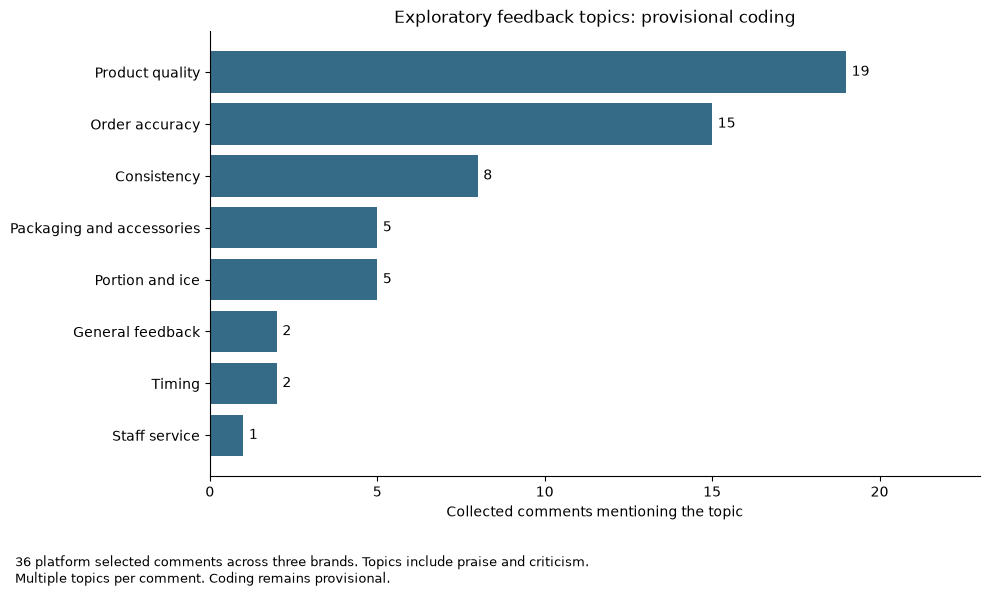

,topic,comments_mentioning_topic,denominator_comments,sample_share_percent
0,Product quality,19,36,52.8
1,Order accuracy,15,36,41.7
2,Consistency,8,36,22.2
3,Portion and ice,5,36,13.9
4,Packaging and accessories,5,36,13.9
5,Timing,2,36,5.6
6,General feedback,2,36,5.6
7,Staff service,1,36,2.8


Source: reports/eda/draft_topic_counts.csv
No brand ranking or population estimate produced.
Chart displayed only. No files changed.


In [3]:
# Load the provisional topic counts exported by Notebook 04.

topic_counts = pd.read_csv(
    eda_path / "draft_topic_counts.csv",
    dtype="string",
)

for column in [
    "comments_mentioning_topic",
    "denominator_comments",
    "sample_share_percent",
]:
    topic_counts[column] = pd.to_numeric(
        topic_counts[column],
        errors="raise",
    )

chart_topics = topic_counts.sort_values("comments_mentioning_topic")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    chart_topics["topic"],
    chart_topics["comments_mentioning_topic"],
    color="#356B87",
)

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_xlim(0, chart_topics["comments_mentioning_topic"].max() + 4)
ax.set_xlabel("Collected comments mentioning the topic")
ax.set_title("Exploratory feedback topics: provisional coding")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02,
    0.02,
    "36 platform selected comments across three brands. "
    "Topics include praise and criticism.\n"
    "Multiple topics per comment. Coding remains provisional.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

display(
    topic_counts[
        [
            "topic",
            "comments_mentioning_topic",
            "denominator_comments",
            "sample_share_percent",
        ]
    ]
)

print("Source: reports/eda/draft_topic_counts.csv")
print("No brand ranking or population estimate produced.")
print("Chart displayed only. No files changed.")

## 4. Proposed Management Actions

### Purpose

Connect the research findings to practical next steps.

These recommendations are proposals for validation.
They are not evidence that implementation will increase sales
or profitability.

Owner roles are suggested responsibilities, not assignments.
Priority reflects the proposed sequence of work.

In [4]:
# Build an evidence linked action register.

recommendations = pd.DataFrame(
    [
        {
            "priority": 1,
            "research_question_ids": "RQ01",
            "evidence": (
                "Six displayed iced menu variants show BFC prices "
                "below the candidate CBTL prices."
            ),
            "evidence_reference": (
                "SRC0030;SRC0031;SRC0032;SRC0121"
            ),
            "proposed_action": (
                "Validate current prices, serving definitions and branch "
                "applicability before preparing price comparison materials."
            ),
            "suggested_owner_role": "Commercial with Operations",
            "success_measure": (
                "Each proposed comparison has documented serving details, "
                "branch scope, channel, price and verification date."
            ),
            "qualification": "Published menu comparison remains provisional.",
        },
        {
            "priority": 1,
            "research_question_ids": "RQ05",
            "evidence": (
                "Provisional coding identifies product quality and "
                "order accuracy as frequent topics in selected comments."
            ),
            "evidence_reference": (
                "SRC0081;SRC0082;SRC0083;draft_topic_counts.csv"
            ),
            "proposed_action": (
                "Review BFC comments and investigate the reported issues "
                "through branch checks of preparation and order completeness."
            ),
            "suggested_owner_role": "Operations with Quality Assurance",
            "success_measure": (
                "Each selected BFC issue has a documented check, finding "
                "and follow up action where required."
            ),
            "qualification": (
                "Comments are customer statements. Pooled topic counts "
                "are not BFC complaint rates."
            ),
        },
        {
            "priority": 1,
            "research_question_ids": "RQ07",
            "evidence": (
                "The directory contains provisional entries, unresolved "
                "aliases and missing operating status dates."
            ),
            "evidence_reference": (
                "branch_directory.csv;branch_reconciliation.csv"
            ),
            "proposed_action": (
                "Resolve branch identities and record operating status, "
                "format and verification date for selected locations."
            ),
            "suggested_owner_role": "Business Development with Operations",
            "success_measure": (
                "Selected entries have confirmed identities or an explicit "
                "unresolved status supported by evidence."
            ),
            "qualification": "Directory entries are not national branch totals.",
        },
        {
            "priority": 2,
            "research_question_ids": "RQ08",
            "evidence": (
                "Recorded franchise offers use different formats "
                "and cost definitions."
            ),
            "evidence_reference": "reports/eda/hypothesis_readiness.csv",
            "proposed_action": (
                "Use a standard quotation checklist covering format, "
                "investment, inclusions, exclusions, taxes and recurring fees."
            ),
            "suggested_owner_role": "Franchise Sales with Finance",
            "success_measure": (
                "Every comparison field is supported by current evidence "
                "or explicitly marked unresolved."
            ),
            "qualification": (
                "Franchise fees and package starting prices "
                "are not equivalent to total investment."
            ),
        },
        {
            "priority": 2,
            "research_question_ids": "RQ09",
            "evidence": (
                "Twelve BFC event variants are recorded. Equivalent "
                "competitor package prices remain unavailable."
            ),
            "evidence_reference": "SRC0089;SRC0091;SRC0092",
            "proposed_action": (
                "Prepare a standard event comparison sheet covering "
                "included cups, duration, staffing, taxes and transport."
            ),
            "suggested_owner_role": "Events Sales with Operations and Finance",
            "success_measure": (
                "Each selected package has documented quantities, "
                "service scope and additional charges."
            ),
            "qualification": (
                "Pax does not establish included cup quantities. "
                "Margin analysis also requires internal costs."
            ),
        },
    ]
)

with pd.option_context("display.max_colwidth", None):
    display(recommendations)

print("Proposed actions:", len(recommendations))
print("Priorities are analyst proposals, not measured impact rankings.")
print("No assignments made. No files changed.")

,priority,research_question_ids,evidence,evidence_reference,proposed_action,suggested_owner_role,success_measure,qualification
0,1,RQ01,Six displayed iced menu variants show BFC prices below the candidate CBTL prices.,SRC0030;SRC0031;SRC0032;SRC0121,"Validate current prices, serving definitions and branch applicability before preparing price comparison materials.",Commercial with Operations,"Each proposed comparison has documented serving details, branch scope, channel, price and verification date.",Published menu comparison remains provisional.
1,1,RQ05,Provisional coding identifies product quality and order accuracy as frequent topics in selected comments.,SRC0081;SRC0082;SRC0083;draft_topic_counts.csv,Review BFC comments and investigate the reported issues through branch checks of preparation and order completeness.,Operations with Quality Assurance,"Each selected BFC issue has a documented check, finding and follow up action where required.",Comments are customer statements. Pooled topic counts are not BFC complaint rates.
2,1,RQ07,"The directory contains provisional entries, unresolved aliases and missing operating status dates.",branch_directory.csv;branch_reconciliation.csv,"Resolve branch identities and record operating status, format and verification date for selected locations.",Business Development with Operations,Selected entries have confirmed identities or an explicit unresolved status supported by evidence.,Directory entries are not national branch totals.
3,2,RQ08,Recorded franchise offers use different formats and cost definitions.,reports/eda/hypothesis_readiness.csv,"Use a standard quotation checklist covering format, investment, inclusions, exclusions, taxes and recurring fees.",Franchise Sales with Finance,Every comparison field is supported by current evidence or explicitly marked unresolved.,Franchise fees and package starting prices are not equivalent to total investment.
4,2,RQ09,Twelve BFC event variants are recorded. Equivalent competitor package prices remain unavailable.,SRC0089;SRC0091;SRC0092,"Prepare a standard event comparison sheet covering included cups, duration, staffing, taxes and transport.",Events Sales with Operations and Finance,"Each selected package has documented quantities, service scope and additional charges.",Pax does not establish included cup quantities. Margin analysis also requires internal costs.


Proposed actions: 5
Priorities are analyst proposals, not measured impact rankings.
No assignments made. No files changed.


In [5]:
# Replace the indirect readiness reference with the underlying dataset.

recommendations.loc[
    recommendations["research_question_ids"].eq("RQ08"),
    "evidence_reference",
] = "data/processed/franchise_offers.csv;SRC0060;SRC0088"

# Save the proposed action register.
# Preserve an existing version before replacement.

from datetime import datetime
import shutil

recommendations_path = project_root / "reports" / "recommendations"
recommendations_path.mkdir(parents=True, exist_ok=True)

output_path = recommendations_path / "management_actions.csv"

if output_path.is_file():
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = recommendations_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    shutil.copy2(output_path, backup_path / output_path.name)

recommendations.to_csv(output_path, index=False)

print("Proposed actions saved:", len(recommendations))
print("Saved:", output_path)
print("Suggested owners remain proposals. No assignments made.")
print("Raw and prepared datasets were not changed.")

Proposed actions saved: 5
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/recommendations/management_actions.csv
Suggested owners remain proposals. No assignments made.
Raw and prepared datasets were not changed.


In [11]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

output_path = (
    project_root / "reports/recommendations/management_actions.csv"
)

recommendations = pd.read_csv(output_path, dtype="string")

local_actions = pd.read_csv(
    project_root / "reports/supplementary/local_commercial_actions.csv",
    dtype="string"
)

local_actions = local_actions.rename(columns={
    "evidence_basis": "evidence"
})

local_actions["priority"] = "1"
local_actions["research_question_ids"] = "RQ01;RQ02;RQ07"
local_actions["evidence_reference"] = (
    "reports/supplementary/local_commercial_actions.csv; "
    "reports/supplementary/local_americano_diagnostic.csv; "
    "reports/supplementary/local_bfc_basket_diagnostic.csv"
)

local_actions["proposed_action"] = (
    local_actions["branch_name"]
    + ": "
    + local_actions["proposed_action"]
)

local_actions["qualification"] = (
    local_actions["validation_required"]
    + " Proposed investigation; impact and profitability unmeasured."
)

additional_actions = pd.DataFrame([
    {
        "priority": "1",
        "research_question_ids": "RQ03;RQ06",
        "evidence": (
            "BFC app promotion and the captured app launching soon "
            "message remain unresolved."
        ),
        "evidence_reference": (
            "SRC0122;SRC0123;SRC0126; "
            "reports/supplementary/digital_evidence_assessment.csv"
        ),
        "proposed_action": (
            "Reconcile the customer app destination, verify participating "
            "branches and document earning, redemption and expiry rules."
        ),
        "suggested_owner_role": "Commercial with Marketing and Technology",
        "success_measure": (
            "One documented customer journey with verified app links, "
            "branch coverage and complete published loyalty rules."
        ),
        "qualification": (
            "Published capabilities do not establish active usage "
            "or retention effects."
        )
    },
    {
        "priority": "2",
        "research_question_ids": "RQ01;RQ08",
        "evidence": (
            "Five Forces ratings remain unresolved because entry barriers, "
            "switching behaviour and supplier evidence are incomplete."
        ),
        "evidence_reference": (
            "reports/supplementary/five_forces_assessment.csv"
        ),
        "proposed_action": (
            "Collect documented opening costs, customer alternatives, "
            "supplier concentration, contracts and input cost histories "
            "before assigning competitive force ratings."
        ),
        "suggested_owner_role": (
            "Commercial with Finance, Operations and Procurement"
        ),
        "success_measure": (
            "Each proposed force rating has documented evidence, "
            "a defined market boundary and an explained assessment."
        ),
        "qualification": (
            "All forces remain unrated until supporting evidence "
            "is sufficient."
        )
    }
])

# Preserve the existing register before replacement.
backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = output_path.parent / "backups" / backup_label
backup_path.mkdir(parents=True, exist_ok=True)
shutil.copy2(output_path, backup_path / output_path.name)

# Use the existing register structure.
recommendation_columns = recommendations.columns.tolist()

recommendations = pd.concat(
    [
        recommendations,
        local_actions[recommendation_columns],
        additional_actions[recommendation_columns]
    ],
    ignore_index=True
).drop_duplicates(
    subset=["research_question_ids", "proposed_action"]
).reset_index(drop=True)

recommendations.to_csv(output_path, index=False)

with pd.option_context("display.max_colwidth", None):
    display(recommendations)

print("Updated recommendations:", len(recommendations))
print("Saved:", output_path)

,priority,research_question_ids,evidence,evidence_reference,proposed_action,suggested_owner_role,success_measure,qualification
0,1,RQ01,Six displayed iced menu variants show BFC prices below the candidate CBTL prices.,SRC0030;SRC0031;SRC0032;SRC0121,"Validate current prices, serving definitions and branch applicability before preparing price comparison materials.",Commercial with Operations,"Each proposed comparison has documented serving details, branch scope, channel, price and verification date.",Published menu comparison remains provisional.
1,1,RQ05,Provisional coding identifies product quality and order accuracy as frequent topics in selected comments.,SRC0081;SRC0082;SRC0083;draft_topic_counts.csv,Review BFC comments and investigate the reported issues through branch checks of preparation and order completeness.,Operations with Quality Assurance,"Each selected BFC issue has a documented check, finding and follow up action where required.",Comments are customer statements. Pooled topic counts are not BFC complaint rates.
2,1,RQ07,"The directory contains provisional entries, unresolved aliases and missing operating status dates.",branch_directory.csv;branch_reconciliation.csv,"Resolve branch identities and record operating status, format and verification date for selected locations.",Business Development with Operations,Selected entries have confirmed identities or an explicit unresolved status supported by evidence.,Directory entries are not national branch totals.
3,2,RQ08,Recorded franchise offers use different formats and cost definitions.,data/processed/franchise_offers.csv;SRC0060;SRC0088,"Use a standard quotation checklist covering format, investment, inclusions, exclusions, taxes and recurring fees.",Franchise Sales with Finance,Every comparison field is supported by current evidence or explicitly marked unresolved.,Franchise fees and package starting prices are not equivalent to total investment.
4,2,RQ09,Twelve BFC event variants are recorded. Equivalent competitor package prices remain unavailable.,SRC0089;SRC0091;SRC0092,"Prepare a standard event comparison sheet covering included cups, duration, staffing, taxes and transport.",Events Sales with Operations and Finance,"Each selected package has documented quantities, service scope and additional charges.",Pax does not establish included cup quantities. Margin analysis also requires internal costs.
5,1,RQ01;RQ02;RQ07,BFC Americano starts at PHP 116; inspected PICKUP Regular is PHP 50. Serving equivalence unresolved.,reports/supplementary/local_commercial_actions.csv; reports/supplementary/local_americano_diagnostic.csv; reports/supplementary/local_bfc_basket_diagnostic.csv,Diliman: Review entry coffee positioning against PICKUP Kalayaan.,Commercial with Operations,A documented comparison with matched product and serving details.,Confirm comparable serving sizes and current branch prices. Proposed investigation; impact and profitability unmeasured.
6,1,RQ01;RQ02;RQ07,Recorded brewed coffee and banana bread total PHP 150. Costs and demand unresolved.,reports/supplementary/local_commercial_actions.csv; reports/supplementary/local_americano_diagnostic.csv; reports/supplementary/local_bfc_basket_diagnostic.csv,Molino III: Assess a coffee and food offer using the existing assortment.,Commercial with Operations and Finance,A costed offer proposal supported by branch sales evidence.,"Confirm item sales, costs, availability and waste. Proposed investigation; impact and profitability unmeasured."
7,1,RQ01;RQ02;RQ07,Recorded brewed coffee and Revel Bar total PHP 136 using captured promotional prices.,reports/supplementary/local_commercial_actions.csv; reports/supplementary/local_americano_diagnostic.csv; reports/supplementary/local_bfc_basket_diagnostic.csv,Jones: Review promotion exposure and a coffee with Revel Bar offer.,Commercial with Operations and Finance,A costed offer proposal with documented promotion terms.,"Confirm promotion funding, serving sizes and item con

Updated recommendations: 11
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/recommendations/management_actions.csv


### Recommendation Status

Eleven proposed actions are saved in
reports/recommendations/management_actions.csv.

They include five original actions, four local branch actions,
one digital ordering and loyalty action, and one action addressing
Five Forces evidence gaps.

Each action retains supporting evidence, a suggested owner role,
a success measure and qualifications.

Owner roles are proposals, not assignments. No sales uplift,
profitability or implementation outcome is established.

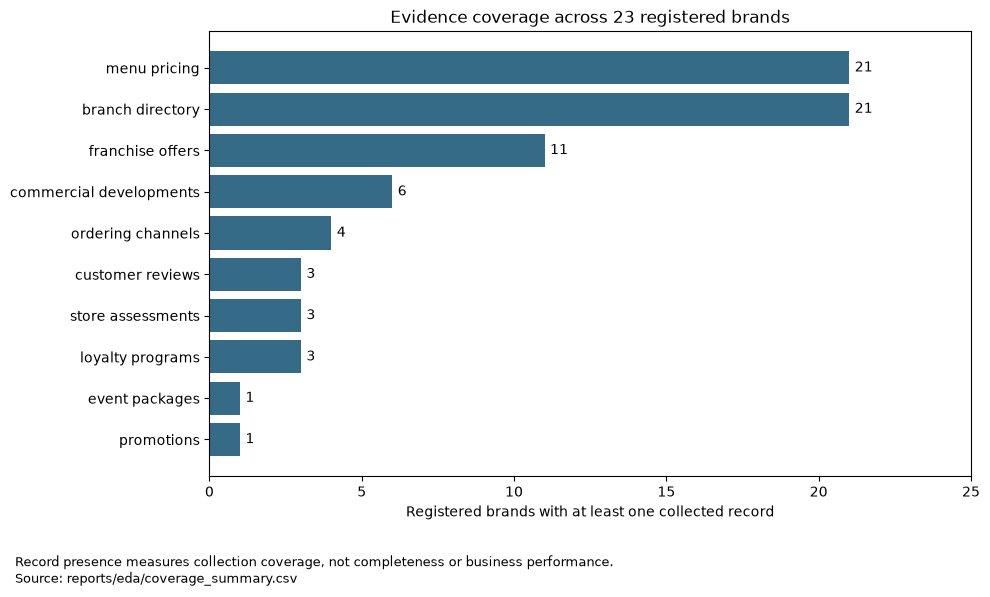

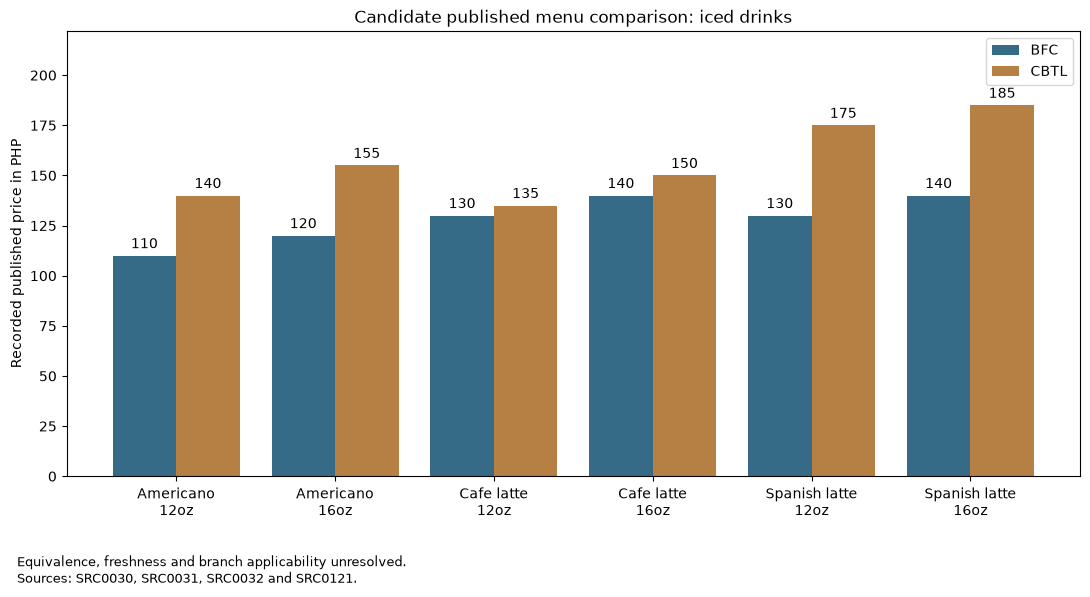

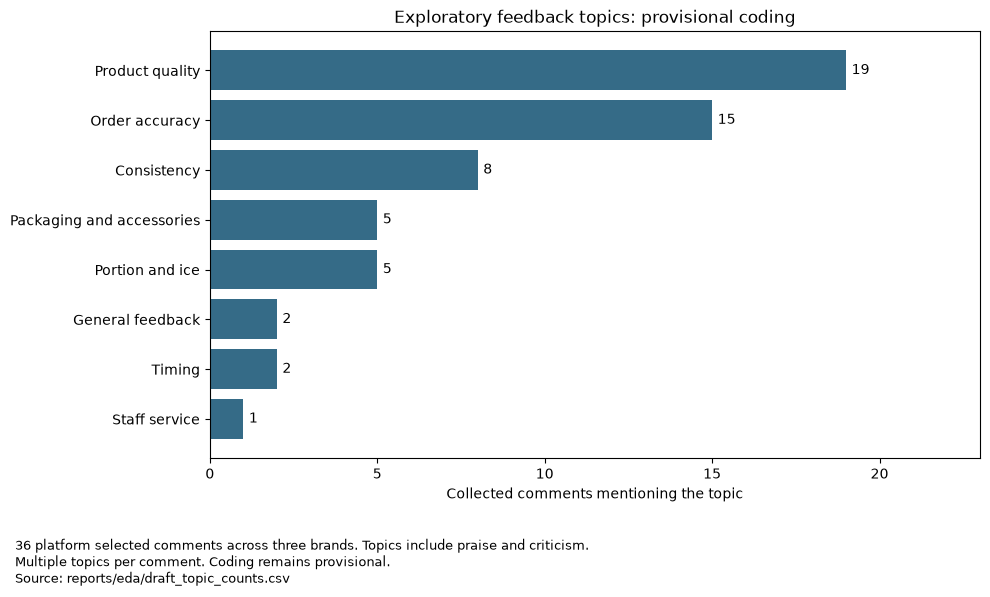

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/evidence_coverage.png
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/candidate_iced_prices.png
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/provisional_feedback_topics.png
Charts exported: 3
Raw and prepared datasets were not changed.


In [6]:
from datetime import datetime
import shutil
import matplotlib.pyplot as plt

charts_path = project_root / "reports" / "figures"
charts_path.mkdir(parents=True, exist_ok=True)

chart_names = [
    "evidence_coverage.png",
    "candidate_iced_prices.png",
    "provisional_feedback_topics.png",
]

# Preserve previously exported charts.

existing_charts = [
    charts_path / name
    for name in chart_names
    if (charts_path / name).is_file()
]

if existing_charts:
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = charts_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    for file_path in existing_charts:
        shutil.copy2(file_path, backup_path / file_path.name)

# 1. Evidence coverage.

chart_data = coverage_summary.sort_values("brands_with_records")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    chart_data["dataset"].str.replace("_", " ", regex=False),
    chart_data["brands_with_records"],
    color="#356B87",
)

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_xlim(0, chart_data["registered_brands"].max() + 2)
ax.set_xlabel("Registered brands with at least one collected record")
ax.set_title("Evidence coverage across 23 registered brands")

fig.text(
    0.02, 0.02,
    "Record presence measures collection coverage, not completeness "
    "or business performance.\n"
    "Source: reports/eda/coverage_summary.csv",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig(charts_path / chart_names[0], dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Candidate published prices.

chart_prices = pricing_features.loc[
    pricing_features["temperature"].eq("Iced")
].sort_values(
    ["comparison_group", "size_label_standardised"]
).copy()

chart_prices["variant"] = (
    chart_prices["comparison_group"]
    + "\n"
    + chart_prices["size_label_standardised"]
)

positions = list(range(len(chart_prices)))

fig, ax = plt.subplots(figsize=(11, 6))

bfc_bars = ax.bar(
    [position - 0.2 for position in positions],
    chart_prices["displayed_price_php_bfc"],
    width=0.4,
    label="BFC",
    color="#356B87",
)

cbtl_bars = ax.bar(
    [position + 0.2 for position in positions],
    chart_prices["displayed_price_php_cbtl"],
    width=0.4,
    label="CBTL",
    color="#B68045",
)

ax.bar_label(bfc_bars, padding=3, fmt="%.0f")
ax.bar_label(cbtl_bars, padding=3, fmt="%.0f")
ax.set_xticks(positions)
ax.set_xticklabels(chart_prices["variant"])
ax.set_ylabel("Recorded published price in PHP")
ax.set_ylim(
    0,
    chart_prices[
        ["displayed_price_php_bfc", "displayed_price_php_cbtl"]
    ].max().max() * 1.2,
)
ax.set_title("Candidate published menu comparison: iced drinks")
ax.legend()

fig.text(
    0.02, 0.02,
    "Equivalence, freshness and branch applicability unresolved.\n"
    "Sources: SRC0030, SRC0031, SRC0032 and SRC0121.",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
fig.savefig(charts_path / chart_names[1], dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Provisional feedback topics.

chart_topics = topic_counts.sort_values("comments_mentioning_topic")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    chart_topics["topic"],
    chart_topics["comments_mentioning_topic"],
    color="#356B87",
)

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_xlim(0, chart_topics["comments_mentioning_topic"].max() + 4)
ax.set_xlabel("Collected comments mentioning the topic")
ax.set_title("Exploratory feedback topics: provisional coding")

fig.text(
    0.02, 0.02,
    "36 platform selected comments across three brands. "
    "Topics include praise and criticism.\n"
    "Multiple topics per comment. Coding remains provisional.\n"
    "Source: reports/eda/draft_topic_counts.csv",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.13, 1, 1])
fig.savefig(charts_path / chart_names[2], dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Confirm that each image was written.

for name in chart_names:
    file_path = charts_path / name

    if not file_path.is_file() or file_path.stat().st_size == 0:
        raise ValueError(f"Chart export failed: {name}")

    print("Saved:", file_path)

print("Charts exported:", len(chart_names))
print("Raw and prepared datasets were not changed.")

## Reporting Conclusion

Three charts were exported to reports/figures.

The evidence coverage chart describes collection breadth
across the 23 registered brands.

The pricing chart presents six candidate iced drink comparisons
between BFC and CBTL. Equivalence, freshness and branch
applicability remain unresolved.

The feedback chart describes topics in 36 platform selected
comments. Coding remains provisional.

Eleven proposed management actions cover the original findings,
four local study branches, digital ordering and loyalty, and
remaining competitive evidence requirements.

No statistical significance, predictive accuracy, financial
benefit or implementation outcome is claimed.

The two local charts show BFC Americano starting prices and competitor
evidence coverage across four selected study areas.

Promotional prices remain distinct from reference prices.
The local shortlist is not a market census, and serving equivalence
remains unresolved.

### Remaining Deliverables

Complete the project data dictionary and database relationship
diagram.

Prepare SQL queries using clearly defined observation units.

Verify the saved management action register and inspect
exported chart labels and footnotes.

Document dependencies and execution instructions, then test
the analytical notebooks from a fresh kernel using the
supplied project files.

The initial descriptive reporting stage is complete.
The broader research study remains partial.

## Local BFC Americano Starting Prices

Compare recorded Foodpanda starting prices across the four study
branches. Show reference prices only where explicitly recorded.

Diliman and Jones include captured promotions. Serving equivalence
and checkout prices remain unresolved.

In [7]:
local_price_verification = pd.read_csv(
    project_root / "data/interim/local_price_verification.csv",
    dtype="string"
)

for column in [
    "displayed_price_php",
    "displayed_reference_price_php"
]:
    local_price_verification[column] = pd.to_numeric(
        local_price_verification[column],
        errors="raise"
    )

bfc_americano_plot = local_price_verification.loc[
    local_price_verification["comparison_role"].eq("BFC study branch")
    & local_price_verification["product_check"].eq("Americano"),
    [
        "business_name",
        "displayed_price_php",
        "displayed_reference_price_php"
    ]
].copy()

display(bfc_americano_plot)

,business_name,displayed_price_php,displayed_reference_price_php
0,Diliman,116.0,145.0
5,Molino III,145.0,<NA>
10,Jones,123.25,145.0
15,T. Chavez,145.0,<NA>


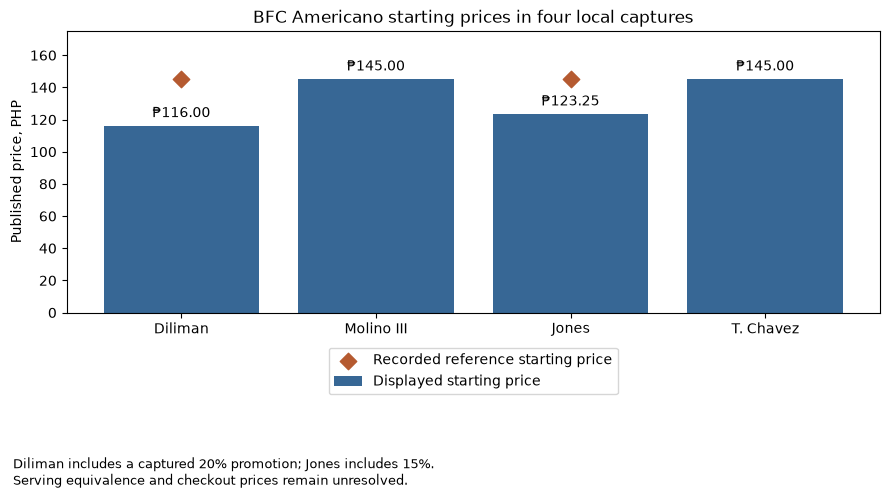

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/local_bfc_americano_starting_prices.png


In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    bfc_americano_plot["business_name"],
    bfc_americano_plot["displayed_price_php"].astype(float),
    color="#376795",
    label="Displayed starting price"
)

reference_prices = bfc_americano_plot.dropna(
    subset=["displayed_reference_price_php"]
)

ax.scatter(
    reference_prices["business_name"],
    reference_prices["displayed_reference_price_php"].astype(float),
    color="#B55A30",
    marker="D",
    s=70,
    label="Recorded reference starting price",
    zorder=3
)

ax.bar_label(bars, fmt="₱%.2f", padding=4)

ax.set(
    title="BFC Americano starting prices in four local captures",
    ylabel="Published price, PHP",
    ylim=(0, 175)
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10)
)

fig.text(
    0.02, 0.02,
    "Diliman includes a captured 20% promotion; Jones includes 15%.\n"
    "Serving equivalence and checkout prices remain unresolved.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.15, 1, 1])

output_path = charts_path / "local_bfc_americano_starting_prices.png"

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", output_path)

### Interpretation

Diliman and Jones show promotional starting prices below their
recorded reference price of PHP 145.

That reference amount matches the displayed starting prices at
Molino III and T. Chavez. Missing reference prices remain unfilled.

These captures do not establish regional pricing policies,
equivalent servings or promotion profitability.

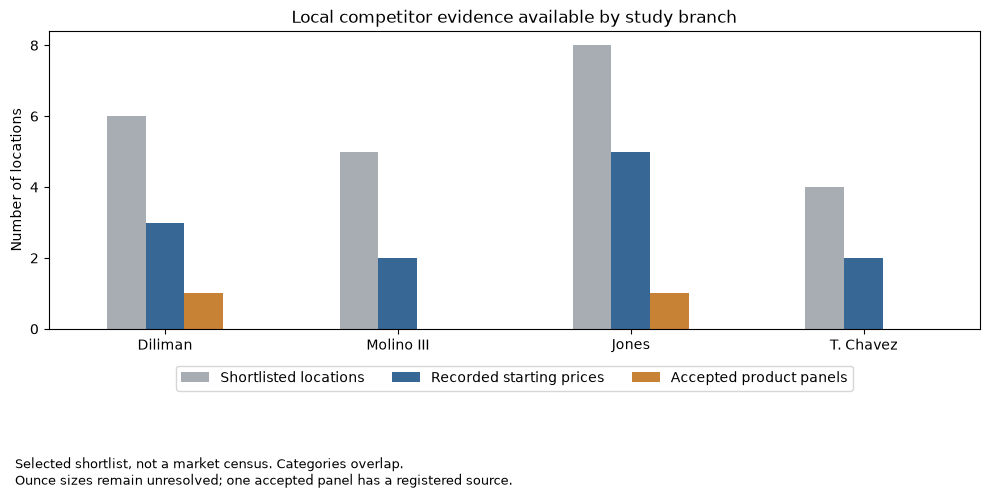

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/figures/local_competitor_evidence_coverage.png


In [9]:
local_site_evidence_summary = pd.read_csv(
    project_root
    / "reports/supplementary/local_site_evidence_summary.csv"
)

local_coverage_plot = local_site_evidence_summary.set_index(
    "branch_name"
)[
    [
        "shortlisted_competitors",
        "recorded_starting_prices",
        "accepted_size_panels"
    ]
]

fig, ax = plt.subplots(figsize=(10, 5))

local_coverage_plot.plot.bar(
    ax=ax,
    color=["#A8ADB3", "#376795", "#C78235"],
    rot=0
)

ax.set(
    title="Local competitor evidence available by study branch",
    xlabel="",
    ylabel="Number of locations"
)

ax.set_yticks(range(0, 10, 2))

ax.legend(
    [
        "Shortlisted locations",
        "Recorded starting prices",
        "Accepted product panels"
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3
)

fig.text(
    0.02, 0.02,
    "Selected shortlist, not a market census. Categories overlap.\n"
    "Ounce sizes remain unresolved; one accepted panel has a registered source.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.16, 1, 1])

output_path = charts_path / "local_competitor_evidence_coverage.png"

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", output_path)

### Local evidence interpretation

Diliman and Jones each have one accepted product panel.
Molino III and T. Chavez have none.

The chart describes collection coverage within the selected shortlist.
It does not measure competitive intensity or rank the four markets.

In [ ]:
chart_files = [
    "evidence_coverage.png",
    "candidate_iced_prices.png",
    "provisional_feedback_topics.png",
    "local_bfc_americano_starting_prices.png",
    "local_competitor_evidence_coverage.png"
]

for filename in chart_files:
    file_path = charts_path / filename

    if not file_path.is_file():
        raise FileNotFoundError(file_path)

    if file_path.stat().st_size == 0:
        raise ValueError(f"Empty chart file: {filename}")

    print("Found:", filename)

In [10]:
chart_files = [
    "evidence_coverage.png",
    "candidate_iced_prices.png",
    "provisional_feedback_topics.png",
    "local_bfc_americano_starting_prices.png",
    "local_competitor_evidence_coverage.png"
]

for filename in chart_files:
    file_path = charts_path / filename

    if not file_path.is_file():
        raise FileNotFoundError(file_path)

    if file_path.stat().st_size == 0:
        raise ValueError(f"Empty chart file: {filename}")

    print("Found:", filename)

Found: evidence_coverage.png
Found: candidate_iced_prices.png
Found: provisional_feedback_topics.png
Found: local_bfc_americano_starting_prices.png
Found: local_competitor_evidence_coverage.png


In [12]:
saved_actions = pd.read_csv(
    project_root / "reports/recommendations/management_actions.csv"
)

print("Saved actions:", len(saved_actions))

display(
    saved_actions[
        ["priority", "suggested_owner_role", "proposed_action"]
    ]
)

Saved actions: 11


,priority,suggested_owner_role,proposed_action
0,1,Commercial with Operations,"Validate current prices, serving definitions a..."
1,1,Operations with Quality Assurance,Review BFC comments and investigate the report...
2,1,Business Development with Operations,Resolve branch identities and record operating...
3,2,Franchise Sales with Finance,Use a standard quotation checklist covering fo...
4,2,Events Sales with Operations and Finance,Prepare a standard event comparison sheet cove...
5,1,Commercial with Operations,Diliman: Review entry coffee positioning again...
6,1,Commercial with Operations and Finance,Molino III: Assess a coffee and food offer usi...
7,1,Commercial with Operations and Finance,Jones: Review promotion exposure and a coffee ...
8,1,Operations with Commercial,T. Chavez: Verify food availability and compet...
9,1,Commercial with Marketing and Technology,"Reconcile the customer app destination, verify..."
